# P3 Movie Genre — Notebook 1: Exploratory Data Analysis

**Goal:** understand the movies, the genre labels, and the plot text in `mpst_imdb_movies.csv` before any modeling.

This notebook only explores — no vectorizing, no modeling. Its one hand-off to Notebooks 2 and 3 is the **vote filter** (`VOTE_MIN`), chosen in §1.3.

| Section | Contents |
|---|---|
| 1 | Movie characteristics: metadata distributions, rating by genre, vote filter |
| 2 | Genre / class balance: positive counts and rates, genre correlation |
| 3 | Text characteristics: synopsis length, distinguishing vocabulary |

`startYear`, `runtimeMinutes`, `averageRating`, and `numVotes` are used here for analysis and filtering only. They are never model inputs.

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

DATA_PATH = Path("../data/mpst_imdb_movies.csv")

**Data location.** The CSV lives in `data/` at the repo root, which `.gitignore` excludes, so the provided dataset is never committed. Download it from the class Google Drive (`Datasets` folder) into `data/` before running.

In [2]:
df = pd.read_csv(DATA_PATH)

META_COLS = ["imdb_id", "primaryTitle", "plot_synopsis", "synopsis_source", "split",
             "startYear", "runtimeMinutes", "averageRating", "numVotes"]
NUM_COLS = ["startYear", "runtimeMinutes", "averageRating", "numVotes"]
GENRE_COLS = [c for c in df.columns if c not in META_COLS]

df[NUM_COLS] = df[NUM_COLS].apply(pd.to_numeric, errors="coerce")

print(f"{len(df):,} movies, {len(GENRE_COLS)} genre columns")
print("Genres:", ", ".join(GENRE_COLS))

14,806 movies, 27 genre columns
Genres: Action, Adventure, Animation, Biography, Comedy, Crime, Documentary, Drama, Family, Fantasy, Film-Noir, Game-Show, History, Horror, Music, Musical, Mystery, News, Reality-TV, Romance, Sci-Fi, Short, Sport, Talk-Show, Thriller, War, Western


Every column that isn't a known metadata column is a genre dummy, so `GENRE_COLS` is derived rather than typed by hand. The numeric metadata is coerced to numbers because IMDB encodes missing values as `\N`, which would otherwise load as text.

In [3]:
pd.concat([df[META_COLS].isna().sum().rename("missing"),
           df[META_COLS].nunique().rename("unique")], axis=1).T

,imdb_id,primaryTitle,plot_synopsis,synopsis_source,split,startYear,runtimeMinutes,averageRating,numVotes
missing,0,0,0,0,0,14,431,43,43
unique,14806,13642,13833,2,3,121,249,84,11446


In [4]:
df["split"].value_counts().to_frame("movies")

,movies
split,
train,9473
test,2966
val,2367


## 1. Movie characteristics

### 1.1 Metadata distributions
`numVotes` spans several orders of magnitude, so it's plotted on a log scale. Runtime is clipped at 240 minutes for display only, so a handful of extreme values don't squash the histogram.

In [5]:
df[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
startYear,14792.0,1988.770,22.909,1896.0,1975.0,1996.0,2007.0,2.026e+03
runtimeMinutes,14375.0,98.825,33.446,1.0,87.0,97.0,112.0,7.780e+02
averageRating,14763.0,6.388,1.156,1.3,5.7,6.5,7.2,9.700e+00
numVotes,14763.0,60278.274,168814.185,7.0,1986.0,8240.0,41566.5,3.266e+06


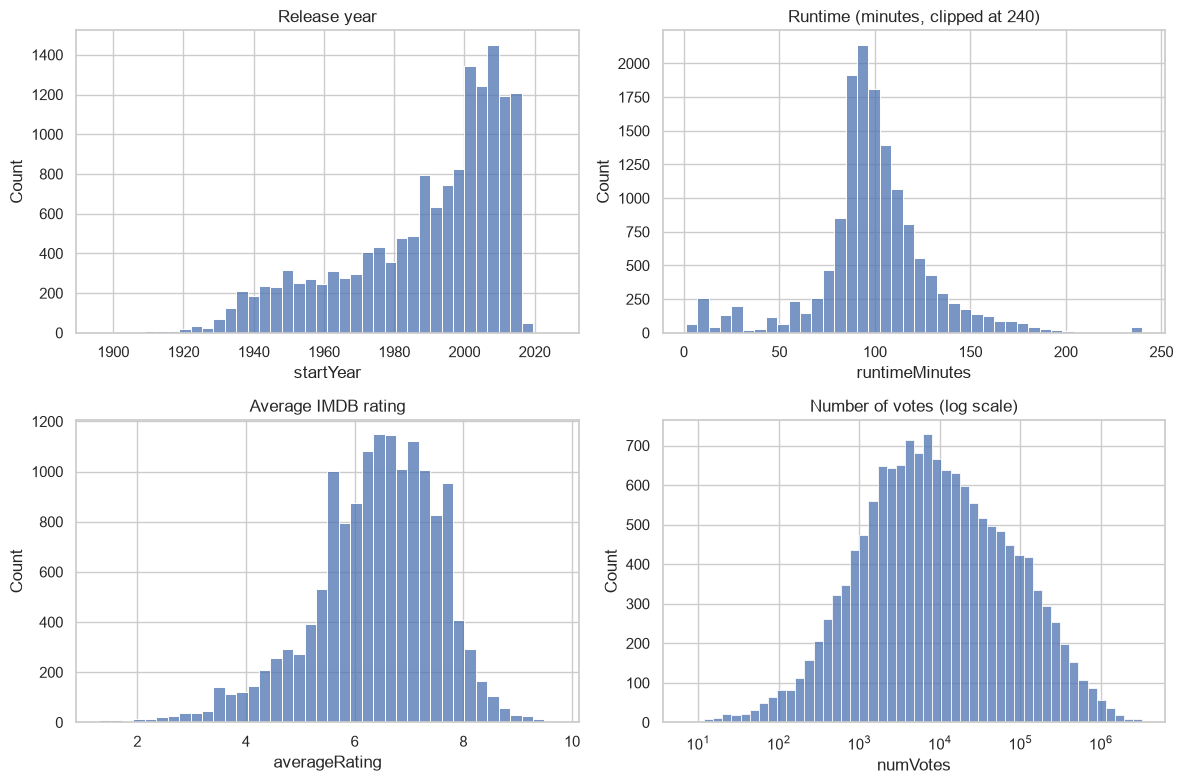

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df["startYear"], bins=40, ax=axes[0, 0])
sns.histplot(df["runtimeMinutes"].clip(upper=240), bins=40, ax=axes[0, 1])
sns.histplot(df["averageRating"], bins=40, ax=axes[1, 0])
sns.histplot(df["numVotes"], bins=50, log_scale=True, ax=axes[1, 1])
axes[0, 0].set_title("Release year")
axes[0, 1].set_title("Runtime (minutes, clipped at 240)")
axes[1, 0].set_title("Average IMDB rating")
axes[1, 1].set_title("Number of votes (log scale)")
plt.tight_layout()
plt.show()

**Reading the distributions.** Release years span 1896–2026, but the middle half of the corpus falls between 1975 and 2007 (median 1996), so it is weighted toward the 1970s–2000s. The typical runtime is about 97 minutes (middle half 87–112), with a few extreme values from 1 to 778 minutes, which is why the plot clips at 240. Ratings are centered around 6.5 (mean 6.39, middle half 5.7–7.2), with a longer tail toward low scores (minimum 1.3, maximum 9.7). `numVotes` is extremely right-skewed: from 7 to 3.27 million, with a median of 8,240 but a mean of 60,278, so a few blockbusters dominate the average and the log scale is needed. 43 movies have no rating or vote count, and 431 have no runtime.

### 1.2 Average rating by genre
A movie with several genres contributes to several boxes. Genres are ordered by median rating.

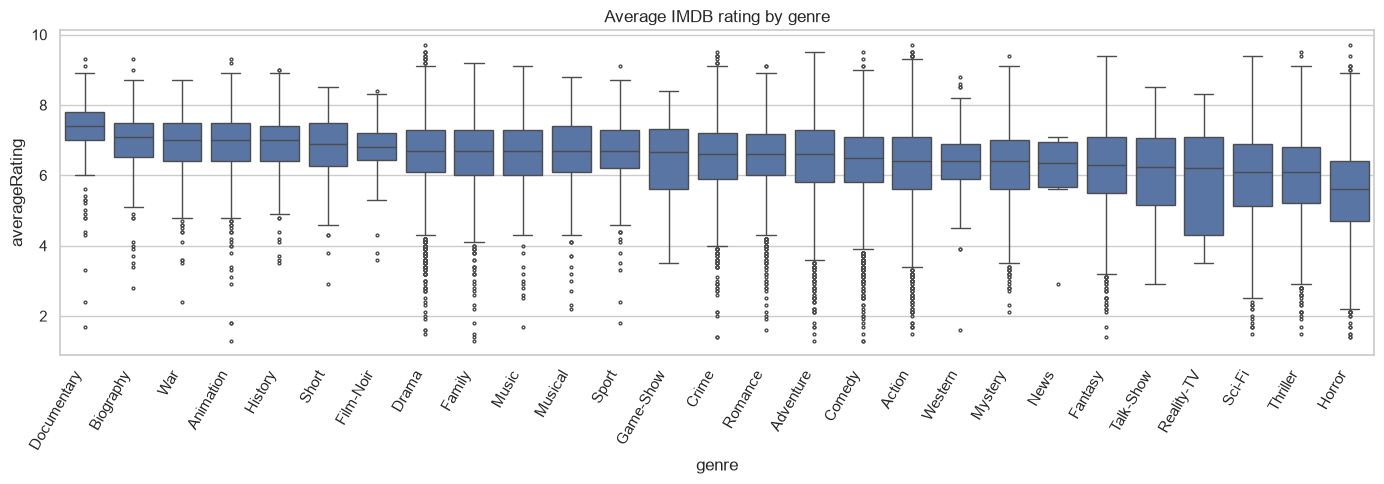

In [7]:
rating_long = (df.melt(id_vars="averageRating", value_vars=GENRE_COLS,
                       var_name="genre", value_name="flag")
                 .query("flag == 1"))
order = rating_long.groupby("genre")["averageRating"].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 5))
sns.boxplot(data=rating_long, x="genre", y="averageRating", order=order, fliersize=2)
plt.xticks(rotation=60, ha="right")
plt.title("Average IMDB rating by genre")
plt.tight_layout()
plt.show()

**Reading the boxes.** Documentary rates highest (median around 7.4), followed by Biography, War, Animation and History (around 7.0). Horror rates clearly lowest (median around 5.6), with Thriller, Sci-Fi and Reality-TV also near the bottom. Even so, the boxes overlap heavily: most genres sit between about 6 and 7.5, so rating says little about genre on its own. This is one more reason rating is used only for analysis and filtering, never as a model input. Small genres such as News, Game-Show and Reality-TV have only a handful of movies, so their boxes are unreliable.

### 1.3 Vote filter
Movies with very few votes tend to have unstable ratings and less reliable genre tags. To choose a minimum, first look at how many rows each candidate threshold would remove from each split.

In [8]:
candidates = [100, 500, 1000, 2500, 5000]
pd.DataFrame({f"< {t:,}": (df["numVotes"] < t).groupby(df["split"]).sum() for t in candidates})

,< 100,< 500,"< 1,000","< 2,500","< 5,000"
split,,,,,
test,44,249,431,818,1154
train,154,777,1452,2749,3948
val,48,209,358,653,936


In [9]:
VOTE_MIN = 1000

below = (df["numVotes"] < VOTE_MIN).groupby(df["split"])
drop_report = pd.DataFrame({"dropped": below.sum(), "total": below.size()})
drop_report["pct_dropped"] = 100 * drop_report["dropped"] / drop_report["total"]
drop_report.loc["all"] = [drop_report["dropped"].sum(), drop_report["total"].sum(),
                          100 * drop_report["dropped"].sum() / drop_report["total"].sum()]
drop_report.round(1)

,dropped,total,pct_dropped
split,,,
test,431,2966,14.5
train,1452,9473,15.3
val,358,2367,15.1
all,2241,14806,15.1


**Decision: `VOTE_MIN = 1000`.** At around a thousand votes, a film's rating and genre tags have been confirmed by a reasonable number of users. The threshold is deliberately modest so the corpus stays large for training.

**Result.** `VOTE_MIN = 1000` drops 2,241 of 14,806 movies (15.1%), leaving 12,522. That is more than we first expected, but we keep 1,000 for two reasons. First, the drop is almost identical across splits (14.5% test, 15.3% train, 15.1% val), so the train/test balance is unchanged. Second, 12,522 movies is still plenty for training, while lowering the cutoff to 500 would keep about 1,000 more movies whose labels rest on very few votes. The 43 movies with no vote count are also removed here.

Notebooks 2 and 3 apply this same filter. The rest of this notebook uses the filtered data, so what we see here matches what the models see.

In [10]:
df = df[df["numVotes"] >= VOTE_MIN].reset_index(drop=True)
print(f"{len(df):,} movies after the vote filter")

12,522 movies after the vote filter


## 2. Genre / class balance

### 2.1 Positive counts and rates for all genres
The red dashed line marks 5%, the minimum positive rate Notebook 2 requires for a selected genre.

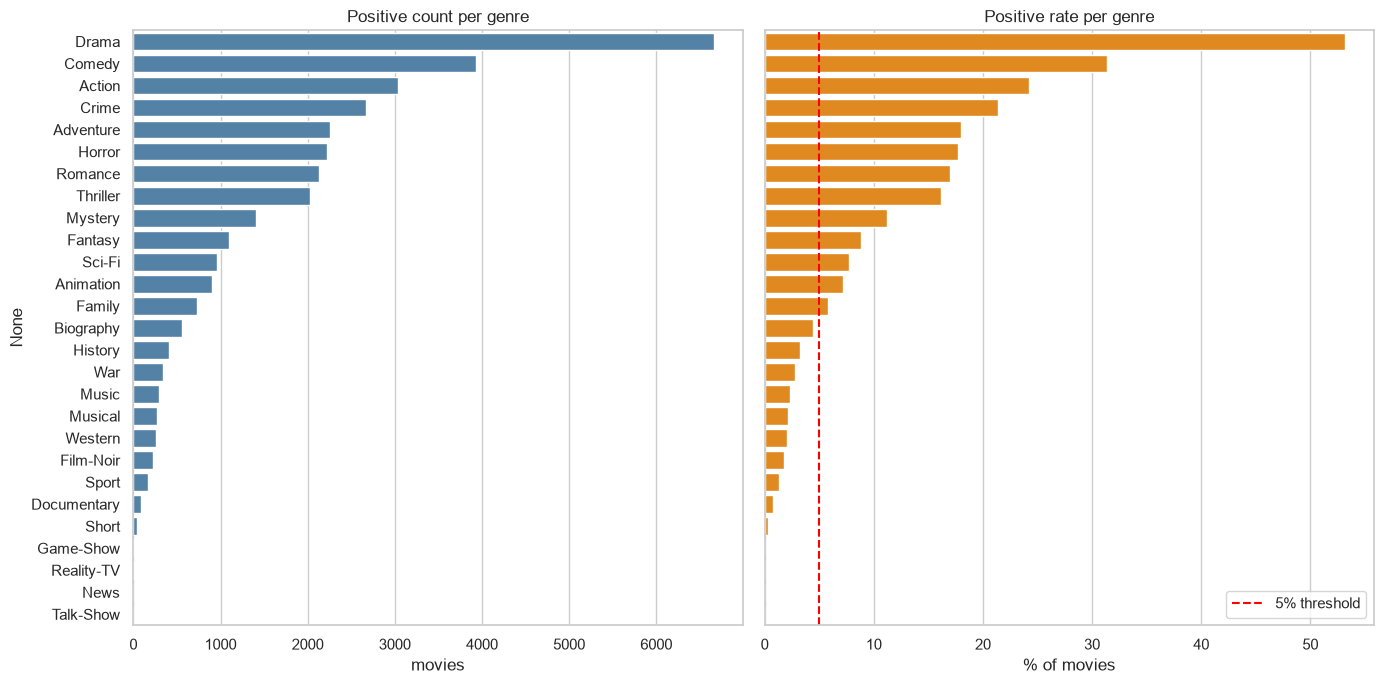

In [11]:
counts = df[GENRE_COLS].sum().sort_values(ascending=False)
rates = 100 * counts / len(df)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
sns.barplot(x=counts.values, y=counts.index, ax=axes[0], color="steelblue")
sns.barplot(x=rates.values, y=rates.index, ax=axes[1], color="darkorange")
axes[1].axvline(5, color="red", ls="--", label="5% threshold")
axes[0].set(title="Positive count per genre", xlabel="movies")
axes[1].set(title="Positive rate per genre", xlabel="% of movies")
axes[1].legend()
plt.tight_layout()
plt.show()

In [12]:
df[GENRE_COLS].sum(axis=1).value_counts().sort_index().rename_axis("genres per movie").to_frame("movies").T

genres per movie,1,2,3
movies,898,3094,8530


**Reading the balance.** Drama dominates: it is tagged on about 53% of movies, well above every other genre. Comedy (about 31%), Action (24%) and Crime (21%) follow, then a cluster of mid-sized genres around 16–18%: Adventure, Horror, Romance and Thriller. Mystery, Fantasy, Sci-Fi, Animation and Family sit between about 6% and 11%. Everything from Biography down falls below the 5% line, and Game-Show, Reality-TV, News and Talk-Show have almost no movies at all.

Most movies carry several genres: 8,530 of 12,522 (68%) have three, 3,094 (25%) have two, and only 898 (7%) have one. So the problem is multi-label, and each genre is its own imbalanced yes/no question. That is why Notebook 2 trains one binary classifier per genre.

**Our genres: Comedy, Horror and Romance.** All three are well above 5% (about 31%, 18% and 17%), so each has enough positives to train and test on. They also cover different kinds of signal: Horror has a strong, distinctive vocabulary, Romance a moderate one, and Comedy depends on tone (§3.2).

### 2.2 Genre correlation
Pearson correlation between the 0/1 dummies (the phi coefficient). Only the lower triangle is shown, since the matrix is symmetric.

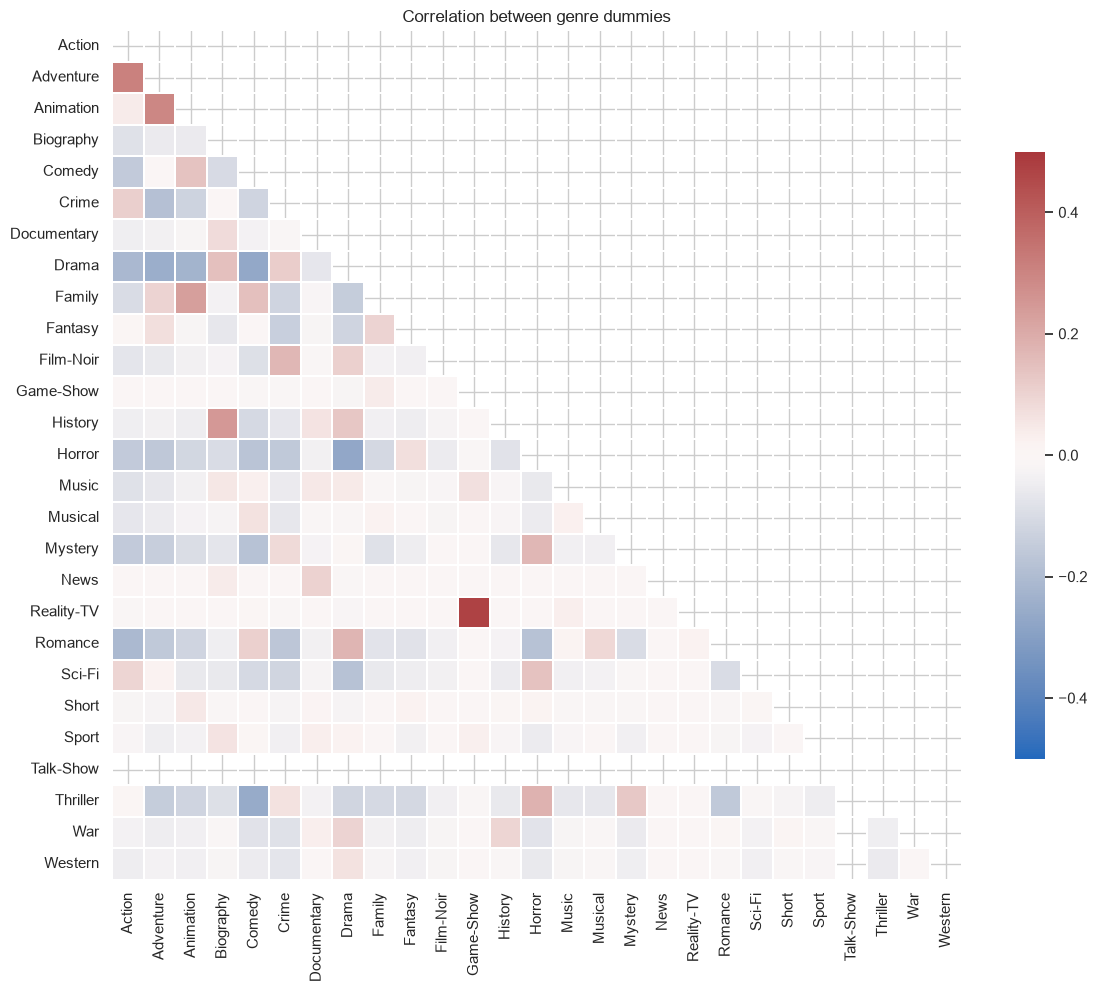

In [13]:
corr = df[GENRE_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-0.5, vmax=0.5,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation between genre dummies")
plt.tight_layout()
plt.show()

**Reading the correlations.** Most pairs are close to zero, so genres are largely independent. The clearest positive pairs are Action–Adventure and Adventure–Animation (about 0.3), Animation–Family and Biography–History (about 0.25), and Horror–Thriller, Crime–Film-Noir and Mystery–Thriller (about 0.2). The single darkest cell, Game-Show–Reality-TV, is an artifact of a few movies tagged with both, not a real pattern. The strongest negative pairs all involve Drama, which is rarely combined with Horror (about −0.3), Comedy, Adventure or Animation. Comedy is also negatively correlated with Thriller, and Romance with Action and Thriller.

For our three genres: Comedy and Romance are mildly positive (they appear together in romantic comedies), while Horror is negatively correlated with both. So the Comedy and Romance classifiers are the most likely to confuse each other, and Horror should separate most cleanly.

## 3. Text characteristics and vocabulary

### 3.1 Synopsis length
Approximate tokens use the common rule of thumb of **≈ 4 characters per token** for English sub-word tokenizers. Synopsis length matters downstream, because sentence-embedding models and LLMs have fixed context windows.

In [14]:
chars = df["plot_synopsis"].str.len()
lengths = pd.DataFrame({
    "characters": chars,
    "words": df["plot_synopsis"].str.split().str.len(),
    "approx_tokens": (chars / 4).round(),
})
lengths.agg(["mean", "median", "min", "max"]).T.round(0)

,mean,median,min,max
characters,5458.0,4010.0,560.0,63959.0
words,952.0,689.0,101.0,11406.0
approx_tokens,1364.0,1002.0,140.0,15990.0


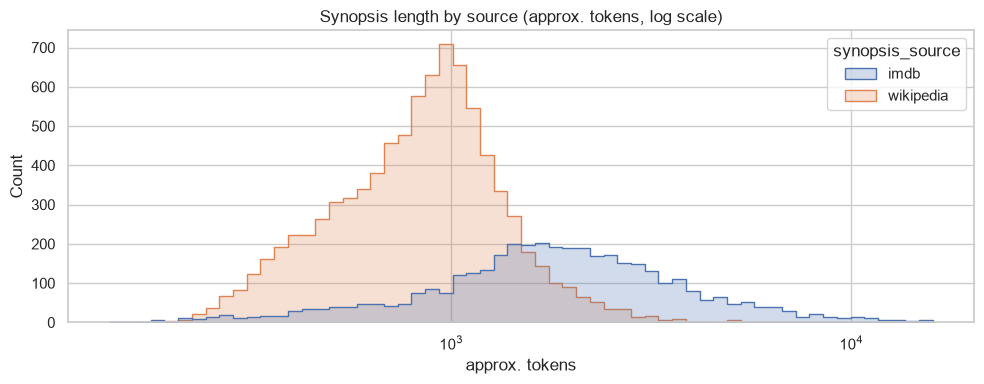

In [15]:
plt.figure(figsize=(10, 4))
sns.histplot(x=lengths["approx_tokens"], hue=df["synopsis_source"], bins=60, log_scale=True, element="step")
plt.title("Synopsis length by source (approx. tokens, log scale)")
plt.xlabel("approx. tokens")
plt.tight_layout()
plt.show()

**Reading the lengths.** The median synopsis is 689 words (about 1,000 tokens), and the mean is higher at 952 words because of a long right tail: the longest runs 11,406 words (about 16,000 tokens), while the shortest is 101 words. The two sources differ clearly. Wikipedia synopses are tightly clustered around 1,000 tokens and rarely go past about 2,000, while IMDB synopses are longer and much more spread out, peaking around 1,500–3,000 tokens with a tail past 10,000. Almost all of the long tail comes from IMDB.

This matters downstream. MiniLM reads at most 256 tokens at a time, so Notebook 2 splits each synopsis into 180-word chunks and averages their embeddings instead of cutting most of the plot off. The LLM teacher's 8,000-character limit leaves the median synopsis (4,010 characters) untouched and mainly truncates the long IMDB ones.

### 3.2 Vocabulary: top terms within genres vs. overall
Each synopsis is tokenized into its set of distinct lowercase words (3+ letters, English stop words removed). **Document frequency** is the share of synopses containing a word. This is plain counting for exploration, not a feature matrix.

Raw frequency alone tends to surface the same narrative words in every genre ("finds", "tells", "kills"). So we also compute **lift** = (document frequency within the genre) / (document frequency overall), restricted to words that appear in at least 5% of the genre's synopses. Lift above 1 means a word is over-represented in that genre.

In [16]:
TOKEN_RE = re.compile(r"[a-z]{3,}")
doc_sets = df["plot_synopsis"].str.lower().map(lambda t: set(TOKEN_RE.findall(t)) - ENGLISH_STOP_WORDS)


def doc_freq(mask):
    counter = Counter()
    for words in doc_sets[mask]:
        counter.update(words)
    return pd.Series(counter, dtype=float) / mask.sum()


overall_df = doc_freq(pd.Series(True, index=df.index))
SHOWCASE = [g for g in ["Horror", "Comedy", "Romance", "Sci-Fi"] if g in GENRE_COLS]
genre_df = {g: doc_freq(df[g] == 1) for g in SHOWCASE}

top_raw = pd.DataFrame({"Overall": overall_df.nlargest(10).index}
                       | {g: genre_df[g].nlargest(10).index for g in SHOWCASE})
top_raw.index = range(1, 11)
top_raw

,Overall,Horror,Comedy,Romance,Sci-Fi
1,time,finds,time,love,time
2,tells,tells,tells,tells,tells
3,later,later,new,time,finds
4,takes,goes,later,later,later
5,finds,away,home,life,takes
6,away,body,takes,new,new
7,goes,dead,goes,day,away
8,home,night,finds,home,goes
9,new,time,away,goes,way
10,man,killed,day,finds,help


The ten most common words in each genre (above) overlap heavily with the overall list. That's why raw frequency is not enough, and why the lift plots below are needed.

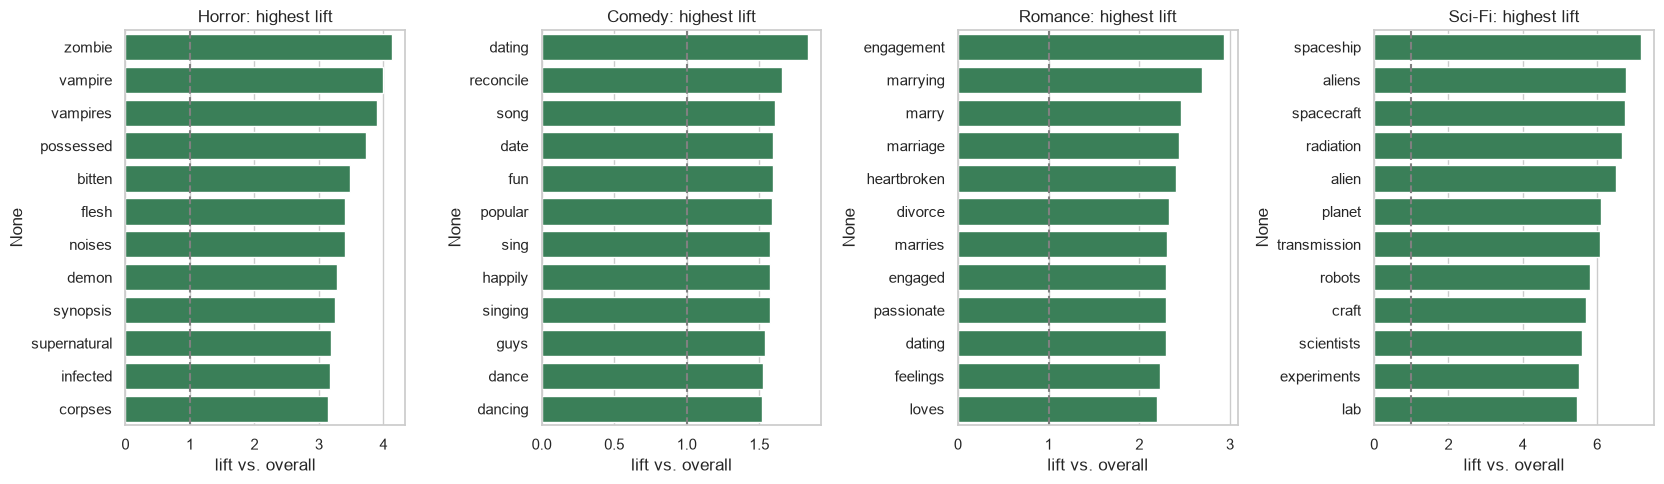

In [17]:
fig, axes = plt.subplots(1, len(SHOWCASE), figsize=(4.2 * len(SHOWCASE), 5))
for ax, g in zip(np.atleast_1d(axes), SHOWCASE):
    supported = genre_df[g][genre_df[g] >= 0.05]
    lift = (supported / overall_df[supported.index]).nlargest(12)
    sns.barplot(x=lift.values, y=lift.index, ax=ax, color="seagreen")
    ax.axvline(1, color="grey", ls="--")
    ax.set(title=f"{g}: highest lift", xlabel="lift vs. overall")
plt.tight_layout()
plt.show()

**Reading the lift.** Three of the four genres have clear, meaningful vocabulary. **Sci-Fi** separates most strongly, with lifts of 6–7 for *spaceship, aliens, spacecraft, radiation, planet* and *robots*. **Horror** comes next, at 3–4 for *zombie, vampire, possessed, bitten, flesh, demon, supernatural* and *corpses*. **Romance** sits at 2–3 for *engagement, marrying, marry, marriage, heartbroken, divorce* and *passionate*. **Comedy** is much weaker: its best words (*dating, reconcile, song, fun, dancing*) reach a lift of only about 1.5–1.8, because comedy comes from tone more than topic. We expect Comedy to be the hardest genre to predict from plot text.

No character or franchise names appear in these top lists, which is good for generalization. One artifact does: *synopsis* has a high lift for Horror. It comes from IMDB's synopsis text (e.g. "Note: this synopsis is for..."), not from the films themselves, and TF-IDF may pick it up as a weak shortcut.

## Summary

- **Corpus:** 14,806 movies with plots, 12,522 after the vote filter (`numVotes` ≥ 1,000), with the drop spread evenly across the train, val and test splits.
- **Imbalance:** Drama is on 53% of movies, and most other genres are minorities. Our three genres have positive rates of about 31% (Comedy), 18% (Horror) and 17% (Romance). 68% of movies carry three genres, so we treat each genre as its own binary problem and use class weights.
- **Correlations:** Genres are mostly independent. Comedy and Romance overlap mildly, while Horror is negatively correlated with both, so Comedy and Romance are the pair most likely to be confused.
- **Length:** The median synopsis is about 1,000 tokens, with a long tail to about 16,000, almost all from IMDB synopses. Fixed-context models need chunking (embeddings) or truncation (the LLM teacher).
- **Vocabulary:** Distinctive words exist for Sci-Fi, Horror and Romance, which justifies a bag-of-words model in Notebook 2. Comedy's vocabulary signal is weak, so it should be the hardest genre.

**Hand-off to Notebooks 2 and 3:** `VOTE_MIN = 1000`.